**1. Imports**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

**2. Load data**

In [2]:
df1 = pd.read_csv("../data/raw/Amazon.csv", encoding="latin-1")
df2 = pd.read_csv("../data/raw/GoogleProducts.csv", encoding="latin-1")
truth = pd.read_csv("../data/raw/Amzon_GoogleProducts_perfectMapping.csv", encoding="latin-1")

print("amazon", df1.shape)
print("google", df2.shape)
print("truth", truth.shape)

df1.head()

amazon (1363, 5)
google (3226, 5)
truth (1300, 2)


,id,title,description,manufacturer,price
0,b000jz4hqo,clickart 950 000 - premier image pack (dvd-rom),NaN,broderbund,0.00
1,b0006zf55o,ca international - arcserve lap/desktop oem 30pk,oem arcserve backup v11.1 win 30u for laptops ...,computer associates,0.00
2,b00004tkvy,noah's ark activity center (jewel case ages 3-8),NaN,victory multimedia,0.00
3,b000g80lqo,peachtree by sage premium accounting for nonpr...,peachtree premium accounting for nonprofits 20...,sage software,599.99
4,b0006se5bq,singing coach unlimited,singing coach unlimited - electronic learning ...,carry-a-tune technologies,99.99


**3. Missing Values**

id                0
title             0
description     115
manufacturer      0
price             0
dtype: int64

id                 0
name               0
description      191
manufacturer    2994
price              0
dtype: int64
amazon missing values (%): id              0.000000
title           0.000000
description     8.437271
manufacturer    0.000000
price           0.000000
dtype: float64
google missing values (%): id               0.000000
name             0.000000
description      5.920645
manufacturer    92.808431
price            0.000000
dtype: float64


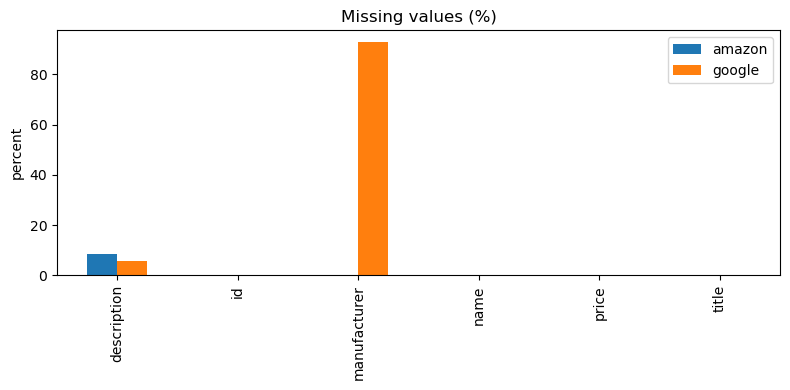

In [3]:
print(df1.isnull().sum())
print()
print(df2.isnull().sum())

# percentage of missing values
amazon_miss = df1.isnull().mean() * 100
google_miss = df2.isnull().mean() * 100

print("amazon missing values (%):", amazon_miss)
print("google missing values (%):", google_miss)

missing = pd.DataFrame({"amazon": amazon_miss, "google": google_miss})
missing.plot(kind="bar", figsize=(8, 4))
plt.title("Missing values (%)")
plt.ylabel("percent")
plt.tight_layout()
plt.savefig("../reports/figures/missing_values.png")
plt.show()

**4. Unique ids**

In [4]:
print("amazon ids unique:", df1["id"].is_unique)
print("google ids unique:", df2["id"].is_unique)

print("total true pairs:", len(truth))
print("amazon records with match:", truth["idAmazon"].nunique(), "out of", len(df1))
print("google records with match:", truth["idGoogleBase"].nunique(), "out of", len(df2))

amazon ids unique: True
google ids unique: True
total true pairs: 1300
amazon records with match: 1113 out of 1363
google records with match: 1291 out of 3226


**5.Matches**

1    969
2    116
3     14
4     13
5      1
Name: count, dtype: int64
1    1282
2       9
Name: count, dtype: int64


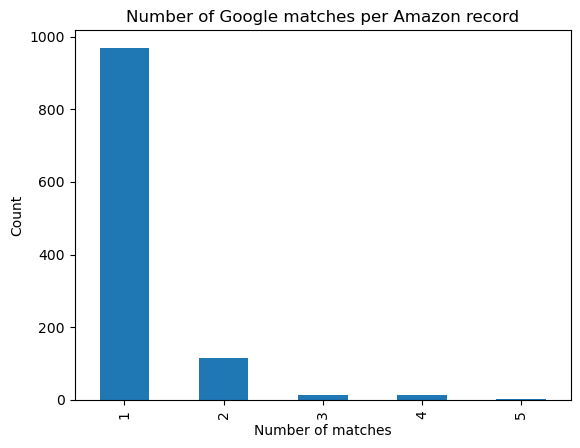

In [5]:
amazon_counts = truth.groupby("idAmazon").size()
print(amazon_counts.value_counts())
google_counts = truth.groupby("idGoogleBase").size()
print(google_counts.value_counts())

amazon_counts.value_counts().plot(kind="bar")
plt.title("Number of Google matches per Amazon record")
plt.xlabel("Number of matches") 
plt.ylabel("Count")
plt.savefig("../reports/figures/amazon_matches.png")
plt.show()

**6.Name Lengths**

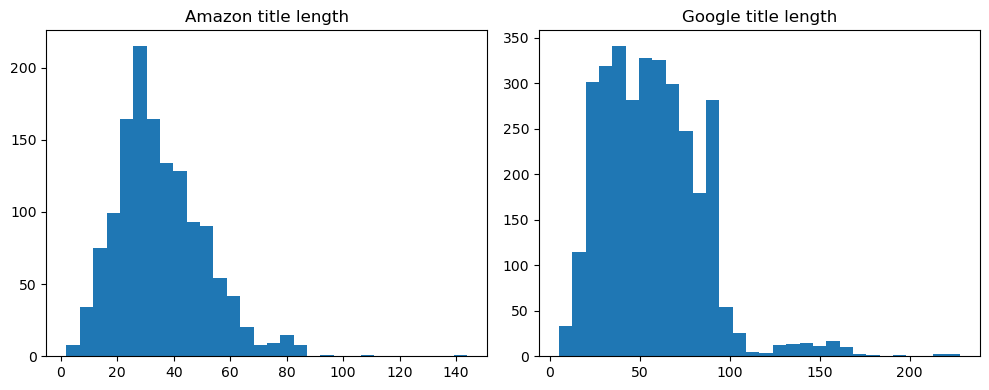

In [6]:
amazon_len= df1["title"].fillna("").str.len()
google_len= df2["name"].fillna("").str.len()

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(amazon_len, bins=30)
plt.title("Amazon title length")

plt.subplot(1, 2, 2)
plt.hist(google_len, bins=30)
plt.title("Google title length")

plt.tight_layout()
plt.savefig("../reports/figures/name_length.png")
plt.show()

**7.Matched pairs**

In [7]:
print(df1.columns.tolist())
print(df2.columns.tolist())

amazon2 = df1.rename(columns={
    "id": "amz_id",
    "title": "amz_name",
    "description": "amz_desc",
    "manufacturer": "amz_manu",
    "price": "amz_price"
})

google2 = df2.rename(columns={
    "id": "ggl_id",
    "name": "ggl_name",
    "description": "ggl_desc",
    "manufacturer": "ggl_manu",
    "price": "ggl_price"
})
pairs = truth.merge(amazon2, left_on="idAmazon", right_on="amz_id")
pairs = pairs.merge(google2, left_on="idGoogleBase", right_on="ggl_id")


print(pairs.shape)
pairs[["amz_name", "ggl_name", "amz_manu", "ggl_manu", "amz_price", "ggl_price"]].sample(15, random_state=1)


['id', 'title', 'description', 'manufacturer', 'price']
['id', 'name', 'description', 'manufacturer', 'price']
(1300, 12)


,amz_name,ggl_name,amz_manu,ggl_manu,amz_price,ggl_price
1109,caillou magical adventures,caillou magical adventures by brighter minds,brighter minds media inc.,NaN,19.99,19.99
370,apple ilife '06 (mac dvd) [older version],ilife '06 mac - apple - ma166z/a,apple computer,NaN,79.00,47.8 gbp
572,adobe creative suite cs3 production premium up...,production prem cs3 mac upgrad,adobe,adobe software,799.00,805.99
239,restricted area,restricted area (win 98 me 2000 xp),whiptail,NaN,19.99,19.99
133,autodesk discreet combustion 4 ( windows ),autodesk combustion 4.0 compositing software -...,autodesk,NaN,0.00,889
1078,microsoft office student and teacher edition 2...,microsoft office 2004 for students and teacher...,microsoft,NaN,149.99,134.99
65,eastwest bsendorfer 290 grand piano virtual in...,east west bosendorfer 290,eastwest,NaN,199.95,175.97
115,tlc dr. seuss reading learning system 2008,encore tlc dr seuss reading learning system 2008,encore,NaN,19.99,17.9
899,aquarium 3 in 1 collection - limited edition f...,encore software 10123 - aquarium 3-in-one limi...,encore software,NaN,19.99,18.97
1171,punch! home design architectura series 18,punch software 41100 punch! home design archit...,punch! software,punch software,129.99,118.99


In [8]:
print((df1["manufacturer"].str.strip() == "").sum())
print((df1["price"].astype(str).str.strip() == "").sum())

0
0


In [9]:
same=0

for i in range(len(pairs)):
  a= str(pairs["amz_name"].iloc[i]).lower().strip()
  g= str(pairs["ggl_name"].iloc[i]).lower().strip()
  if a==g:
    same+=1
    
print("Number of pairs with same name:", same, "out of", len(pairs))
print("Percentage of pairs with same name:", same/len(pairs)*100, "%")

Number of pairs with same name: 44 out of 1300
Percentage of pairs with same name: 3.3846153846153846 %


**8. Price check**

In [10]:
pairs["amz_price"] = pd.to_numeric(pairs["amz_price"], errors="coerce")
pairs["ggl_price"] = pd.to_numeric(pairs["ggl_price"], errors="coerce")


both = pairs.dropna(subset=["amz_price", "ggl_price"])
print("pairs with both prices:", len(both), "out of", len(pairs))
diff = (both["amz_price"] - both["ggl_price"]).abs()
print(diff.describe())

pairs with both prices: 1298 out of 1300
count     1298.000000
mean       398.134268
std       4480.558602
min          0.000000
25%          1.812500
50%          6.970000
75%         22.900000
max      69216.950000
dtype: float64


In [11]:
print((pairs["amz_price"]==0).sum())
print((pairs["ggl_price"]==0).sum())

136
0


In [12]:
ok = pairs[(pairs["amz_price"] > 0) & (pairs["ggl_price"] > 0)].copy()
bigger = ok[["amz_price", "ggl_price"]].max(axis=1)
ok["rel_diff"] = (ok["amz_price"] - ok["ggl_price"]).abs() / bigger


print(ok["rel_diff"].describe())
print("within 10%:", (ok["rel_diff"] < 0.1).mean())
print("within 30%:", (ok["rel_diff"] < 0.3).mean())
print("above 50%:", (ok["rel_diff"] > 0.5).mean())
print()

count    1163.000000
mean        0.157535
std         0.163149
min         0.000000
25%         0.035875
50%         0.116686
75%         0.224748
max         0.875047
Name: rel_diff, dtype: float64
within 10%: 0.4402407566638005
within 30%: 0.8357695614789338
above 50%: 0.049011177987962166



In [13]:
print((df1["price"] == 0).sum(), "of", len(df1))

199 of 1363


## Key findings

**Dataset size**
- Amazon has 1,363 records and Google has 3,226 records, so comparing every pair means about 4.4 million comparisons. Blocking is needed.
- The ground truth has 1,300 true matching pairs.

**Match structure**
- 1,113 Amazon records (81.7%) have at least one Google match, and 250 Amazon records (18.3%) have none, so the model must be able to predict "no match".
- Most Amazon records have exactly one match (969), but 144 have 2 to 5 matches (116 have 2, 14 have 3, 13 have 4, 1 has 5). The output must be a list of matches, not a single match.
- Only 1,291 of 3,226 Google records (40%) have a match, so 60% of Google records are distractors.
- From the Google side matching is almost one-to-one: 1,282 Google records match one Amazon record and only 9 match two.

**Missing values**
- Google manufacturer is missing for 92.8% of records, so it cannot be used directly. The brand has to be extracted from the product name.
- Amazon manufacturer and price have no missing values and no blank strings.
- Description is missing for 8.4% of Amazon records and 5.9% of Google records.

**Name similarity**
- Only 44 of 1,300 matched pairs (3.4%) have identical names, so exact matching is not enough and fuzzy matching is required.

**Price**
- Price is available on both sides for 1,298 of 1,300 matched pairs.
- 136 matched pairs have an Amazon price of 0, which means the price is unknown, not a real price. Google has no zero prices. Zero should be treated as missing.
- The raw price difference has extreme outliers (mean 398, max 69,217, median 6.97), so the mean is misleading.
- For pairs with real prices on both sides (1,163 pairs), the median relative difference is about 12% and 75% of pairs are within about 22%. Price agrees loosely for true matches, so it is a weak signal and should be used as relative difference, not as a hard rule.

**What this means for the next steps**
- Cleaning: lowercase, remove HTML and punctuation, treat price 0 as missing.
- Features: extract brand and model/version numbers from the product name.
- Blocking: needed to reduce the 4.4 million pairs, with enough candidates per record to cover up to 5 matches.
- Evaluation: use precision, recall and F0.5, and make sure records with no match are handled correctly.